<a href="https://colab.research.google.com/github/erickcorrea3092/Python-basics-course/blob/main/9_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from sklearn.datasets import load_digits
import matplotlib.pyplot as plt

In [ ]:
digits = load_digits() # Se cargan el dataset

In [ ]:
digits

{'data': array([[ 0.,  0.,  5., ...,  0.,  0.,  0.],
        [ 0.,  0.,  0., ..., 10.,  0.,  0.],
        [ 0.,  0.,  0., ..., 16.,  9.,  0.],
        ...,
        [ 0.,  0.,  1., ...,  6.,  0.,  0.],
        [ 0.,  0.,  2., ..., 12.,  0.,  0.],
        [ 0.,  0., 10., ..., 12.,  1.,  0.]]),
 'target': array([0, 1, 2, ..., 8, 9, 8]),
 'frame': None,
 'feature_names': ['pixel_0_0',
  'pixel_0_1',
  'pixel_0_2',
  'pixel_0_3',
  'pixel_0_4',
  'pixel_0_5',
  'pixel_0_6',
  'pixel_0_7',
  'pixel_1_0',
  'pixel_1_1',
  'pixel_1_2',
  'pixel_1_3',
  'pixel_1_4',
  'pixel_1_5',
  'pixel_1_6',
  'pixel_1_7',
  'pixel_2_0',
  'pixel_2_1',
  'pixel_2_2',
  'pixel_2_3',
  'pixel_2_4',
  'pixel_2_5',
  'pixel_2_6',
  'pixel_2_7',
  'pixel_3_0',
  'pixel_3_1',
  'pixel_3_2',
  'pixel_3_3',
  'pixel_3_4',
  'pixel_3_5',
  'pixel_3_6',
  'pixel_3_7',
  'pixel_4_0',
  'pixel_4_1',
  'pixel_4_2',
  'pixel_4_3',
  'pixel_4_4',
  'pixel_4_5',
  'pixel_4_6',
  'pixel_4_7',
  'pixel_5_0',
  'pixel_5_1',
 

In [ ]:
print(f'Las dimensiones de las imagenes son {digits.images.shape}')

Las dimensiones de las imagenes son (1797, 8, 8)


In [ ]:
print(digits.images[0]) # se muestra los datos (matriz) de la primer imagen

[[ 0.  0.  5. 13.  9.  1.  0.  0.]
 [ 0.  0. 13. 15. 10. 15.  5.  0.]
 [ 0.  3. 15.  2.  0. 11.  8.  0.]
 [ 0.  4. 12.  0.  0.  8.  8.  0.]
 [ 0.  5.  8.  0.  0.  9.  8.  0.]
 [ 0.  4. 11.  0.  1. 12.  7.  0.]
 [ 0.  2. 14.  5. 10. 12.  0.  0.]
 [ 0.  0.  6. 13. 10.  0.  0.  0.]]


In [ ]:
print(digits.data[0])   # se muestra los datos (vector) de la primer imagen

[ 0.  0.  5. 13.  9.  1.  0.  0.  0.  0. 13. 15. 10. 15.  5.  0.  0.  3.
 15.  2.  0. 11.  8.  0.  0.  4. 12.  0.  0.  8.  8.  0.  0.  5.  8.  0.
  0.  9.  8.  0.  0.  4. 11.  0.  1. 12.  7.  0.  0.  2. 14.  5. 10. 12.
  0.  0.  0.  0.  6. 13. 10.  0.  0.  0.]


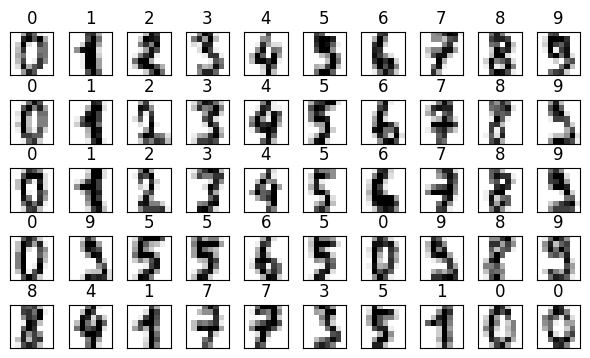

In [ ]:
figure, axes = plt.subplots(nrows=5, ncols=10, figsize=(6, 4))
for item in zip(axes.ravel(), digits.images, digits.target):
    axes, image, target = item
    axes.imshow(image, cmap=plt.cm.gray_r)
    axes.set_xticks([])
    axes.set_yticks([])
    axes.set_title(target)
    plt.tight_layout()

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(digits.data, digits.target, test_size=0.20)

In [ ]:
print(f'Datos de entrenamiento {X_train.shape}')
print(f'Etiquetas de entrenamiento {y_train.shape}')
print(f'Datos de prueba {X_test.shape}')
print(f'Etiquetas de prueba {y_test.shape}')

Datos de entrenamiento (1437, 64)
Etiquetas de entrenamiento (1437,)
Datos de prueba (360, 64)
Etiquetas de prueba (360,)


In [ ]:
from sklearn.neighbors import KNeighborsClassifier

modelo = KNeighborsClassifier(n_neighbors=5) # modelo clasificador
modelo.fit(X=X_train, y=y_train) # entrenamiento del clasificador

KNeighborsClassifier()

In [ ]:
predicted = modelo.predict(X=X_test)
expected = y_test

# prediccón sobre 30 elementos
print(f'La predicción es {predicted[:30]}')
print(f'Lo esperado es   {expected[:30]}')

La predicción es [4 2 4 5 6 7 6 7 8 2 3 9 9 2 4 0 7 1 6 7 2 6 6 5 6 9 9 5 8 4]
Lo esperado es   [4 2 4 5 6 7 6 7 9 2 3 9 9 2 4 0 7 1 6 7 2 6 6 5 6 9 9 5 8 4]


In [ ]:
error = 0
for (p, e) in zip(predicted, expected):
    if p != e:
       error += 1
print(f'El error en porcentaje es de {(error/len(predicted)*100):.2f}')

El error en porcentaje es de 1.94


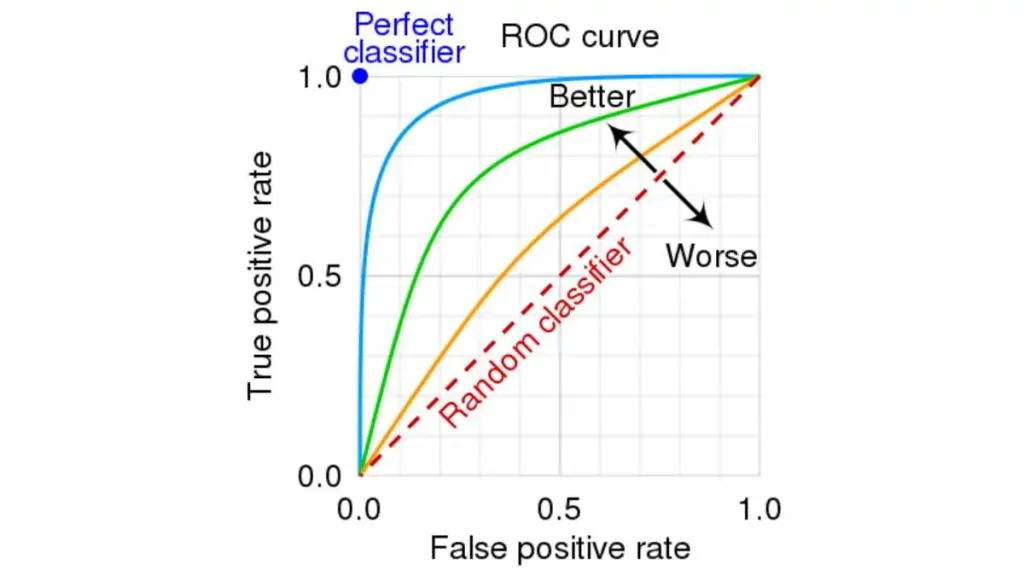

Una curva ROC (Característica Operacional del Receptor) es un gráfico que evalúa el rendimiento de un modelo de clasificación o de una prueba diagnóstica. Se construye graficando la tasa de verdaderos positivos (TPR) frente a la tasa de falsos positivos (FPR) en todos los puntos de corte posibles. Un modelo perfecto tiene una curva que llega a la esquina superior izquierda (0, 1), mientras que una curva en diagonal representa una prueba aleatoria.  

¿Qué muestra la curva ROC?     

Eje Y: Tasa de verdaderos positivos (TPR), también conocida como sensibilidad. Eje X: Tasa de falsos positivos (FPR), que es especificidad.

Puntos de la curva: Cada punto representa un resultado para un umbral de clasificación específico.               

¿Cómo se utiliza?     

Evaluación de modelos: Permite ver cómo cambia el rendimiento de un modelo a medida que se varía el umbral de decisión.

Selección de punto de corte: Ayuda a encontrar un punto de corte óptimo que ofrezca un buen equilibrio entre sensibilidad y especificidad para una prueba.

Comparación de pruebas: El área bajo la curva ROC (AUC, por sus siglas en inglés) cuantifica la capacidad de la prueba para distinguir entre clases. Un AUC mayor indica un mejor rendimiento.          


Origen del término: El término ROC se acuñó en la década de 1940 durante la Segunda Guerra Mundial para evaluar el rendimiento de los operadores de radar en la detección de señales.

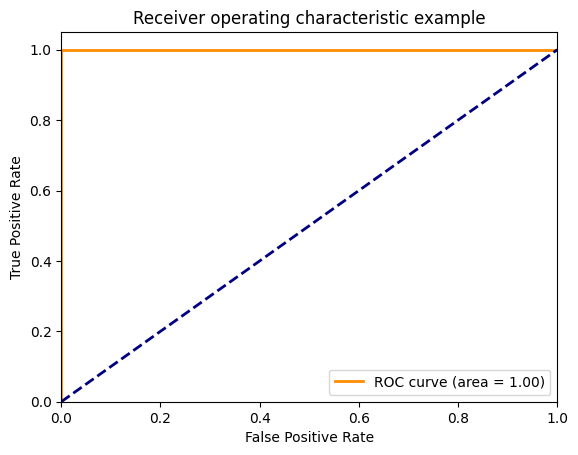

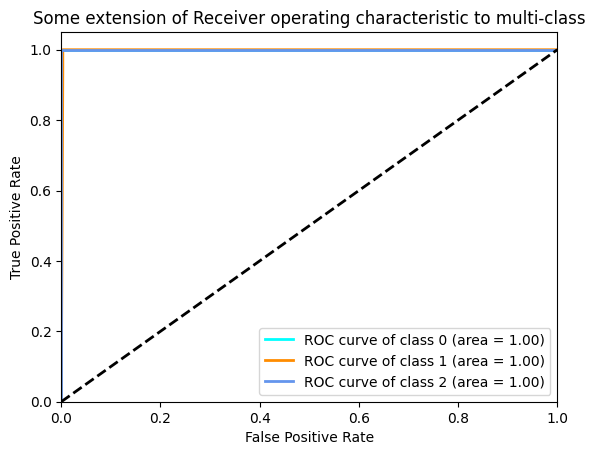

In [ ]:
# gráfica ROC DEL COMPORTAMIENTO

from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import numpy as np


# Binarize the output
y_test_bin = label_binarize(y_test, classes=np.unique(y_test))
n_classes = y_test_bin.shape[1]

# Compute probabilities for each class
y_score = modelo.predict_proba(X_test)


# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute micro-average ROC curve and ROC area
fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), y_score.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# Plot ROC curves for the multiclass problem
plt.figure()
lw = 2
plt.plot(fpr[2], tpr[2], color='darkorange',
         lw=lw, label='ROC curve (area = %0.2f)' % roc_auc[2])
plt.plot([0, 1], [0, 1], color='navy', lw=lw, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic example')
plt.legend(loc="lower right")
plt.show()


# Plot all ROC curves
plt.figure()
colors = ['aqua', 'darkorange', 'cornflowerblue']
for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=lw,
             label='ROC curve of class {0} (area = {1:0.2f})'
             ''.format(i, roc_auc[i]))

plt.plot([0, 1], [0, 1], 'k--', lw=lw)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Some extension of Receiver operating characteristic to multi-class')
plt.legend(loc="lower right")
plt.show()